In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


In [4]:

df = pd.read_csv("/Users/kierachiu/Documents/IDX Exchange/IDX-Exchange-Data-Science/02_cleaned_data.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Dataset shape: (106501, 20)


,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,Latitude,Longitude,ParkingTotal,PostalCode,FireplaceYN,NewConstructionYN,City,CountyOrParish,ViewYN,MLSAreaMajor,AttachedGarageYN,ClosePrice,CloseDate,closing_month,dataset_split
0,1810.0,3.0,3.0,5318.0,1988.0,33.157973,-117.253250,4.0,92081,True,False,Vista,San Diego,False,92081 - Vista,True,1040000.0,2025-07-31,2025-07,train
1,2987.0,3.0,3.0,12632.0,1954.0,33.803727,-116.534532,6.0,92264,True,False,Palm Springs,Riverside,True,334 - South End Palm Springs,True,2400000.0,2025-07-31,2025-07,train
2,2007.0,4.0,3.0,3600.0,1968.0,36.603859,-121.868261,2.0,93940,True,False,Monterey,Monterey,True,699 - Not Defined,True,1908500.0,2025-07-23,2025-07,train
3,2234.0,4.0,4.0,17248.0,1948.0,33.151355,-117.101143,2.0,92026,False,NaN,Escondido,San Diego,True,92026 - Escondido,True,1050000.0,2025-07-29,2025-07,train
4,2967.0,3.0,3.0,10200.0,2000.0,37.390272,-122.110274,1.0,94022,True,False,Los Altos,Santa Clara,False,699 - Not Defined,True,5900000.0,2025-07-31,2025-07,train


['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'LotSizeSquareFeet', 'YearBuilt', 'Latitude', 'Longitude', 'ParkingTotal', 'PostalCode', 'FireplaceYN', 'NewConstructionYN', 'City', 'CountyOrParish', 'ViewYN', 'MLSAreaMajor', 'AttachedGarageYN', 'ClosePrice', 'CloseDate', 'closing_month', 'dataset_split']


In [11]:
# same split as in 03_baseline_model
summary = json.load(open("02_run_summary.json"))

best_X = summary["best_X"]
test_month = summary["test_month"]
low = summary["lower_threshold"]
high = summary["upper_threshold"]

# Define numeric features
numeric_features = [
    "LivingArea",
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "LotSizeSquareFeet",
    "YearBuilt",
    "Latitude",
    "Longitude",
    "ParkingTotal"
]

# Define categorical features
categorical_features = [
    "PostalCode",
    "FireplaceYN",
    "NewConstructionYN",
    "City",
    "CountyOrParish",
    "ViewYN",
    "MLSAreaMajor",
    "AttachedGarageYN"
]

# Combine all features and define target
features = numeric_features + categorical_features
target = "ClosePrice"

# Load cleaned dataset from Week 3
df = pd.read_csv(
    "02_cleaned_data.csv",
    dtype={"PostalCode": "string"},
    parse_dates=["CloseDate"],
    low_memory=False
)

# Reuse the original train/test split
train = df[df["dataset_split"] == "train"].copy()
test = df[df["dataset_split"] == "test"].copy()

# Convert categorical values to strings and fill missing values
for d in (train, test):
    for c in categorical_features:
        d[c] = d[c].astype("string").fillna("Missing")

# Separate features (X) and target (y)
X_train = train[features]
y_train = train[target].to_numpy(float)

X_test = test[features]
y_test = test[target].to_numpy(float)

# Display dataset information
print(f"Training window: {best_X} months | Test month: {test_month}")
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Training price bounds: ${low:,.0f} to ${high:,.0f}")

Training window: 9 months | Test month: 2026-04
Train: (94162, 16) | Test: (12339, 16)
Training price bounds: $190,000 to $8,750,000


In [19]:
# Add preprocessing pipeline

# Numeric columns: fill missing values with median and standardize
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical columns: fill missing values and one-hot encode
# PostalCode remains a string and is treated as categorical
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Route numeric and categorical columns through their transformers
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Combine preprocessing and Decision Tree into one pipeline
decision_tree = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=5,
        random_state=42
    ))
])

# Train Decision Tree with preprocessing
decision_tree.fit(X_train, y_train)

# Predict on test data
dt_predictions = decision_tree.predict(X_test)

# Evaluate model
dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Test R²:", round(dt_r2, 4))

Decision Tree Test R²: 0.7419


In [21]:
# Random Forest with preprocessing pipeline
random_forest = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=15,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest with preprocessing
random_forest.fit(X_train, y_train)

# Predict on test data
rf_predictions = random_forest.predict(X_test)

# Evaluate model
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Test R²:", round(rf_r2, 4))

Random Forest Test R²: 0.8455


In [27]:
# Import trained Linear Regression model from notebook 03
import joblib

baseline_model = joblib.load("03_baseline_model.joblib")

# Generate predictions
# Baseline model was trained on log(ClosePrice)
lr_train_predictions = np.exp(baseline_model.predict(X_train))
lr_predictions = np.exp(baseline_model.predict(X_test))

# Calculate evaluation metrics
lr_r2 = r2_score(y_test, lr_predictions)
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_mdape = np.median(
    np.abs(lr_predictions - y_test) / y_test
) * 100

print("Linear Regression Results")
print(f"R²:    {lr_r2:.4f}")
print(f"MAE:   ${lr_mae:,.2f}")
print(f"RMSE:  ${lr_rmse:,.2f}")
print(f"MdAPE: {lr_mdape:.2f}%")

Linear Regression Results
R²:    0.7582
MAE:   $197,404.61
RMSE:  $488,106.03
MdAPE: 10.00%


In [37]:
# Compare Linear Regression, Decision Tree, and Random Forest

models = {
    "Linear Regression": baseline_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

comparison_results = []

for name, model in models.items():

    # Generate test predictions
    predictions = model.predict(X_test)

    # Linear Regression was trained on log prices
    if name == "Linear Regression":
        predictions = np.exp(predictions)

    # Calculate evaluation metrics
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mdape = np.median(
        np.abs(predictions - y_test) / y_test
    ) * 100

    # Store model results
    comparison_results.append({
        "Model": name,
        "R²": r2,
        "MAE": mae,
        "RMSE": rmse,
        "MdAPE (%)": mdape
    })

# Create comparison DataFrame
comparison = pd.DataFrame(comparison_results)

# Rank models by test R² (higher is better)
comparison = comparison.sort_values(
    by="R²",
    ascending=False
).reset_index(drop=True)

# Display model comparison
display(comparison.round(4))

,Model,R²,MAE,RMSE,MdAPE (%)
0,Random Forest,0.8455,209565.4033,390223.4322,11.2798
1,Linear Regression,0.7582,197404.6139,488106.0251,9.9958
2,Decision Tree,0.7419,288759.4963,504269.5627,16.2941


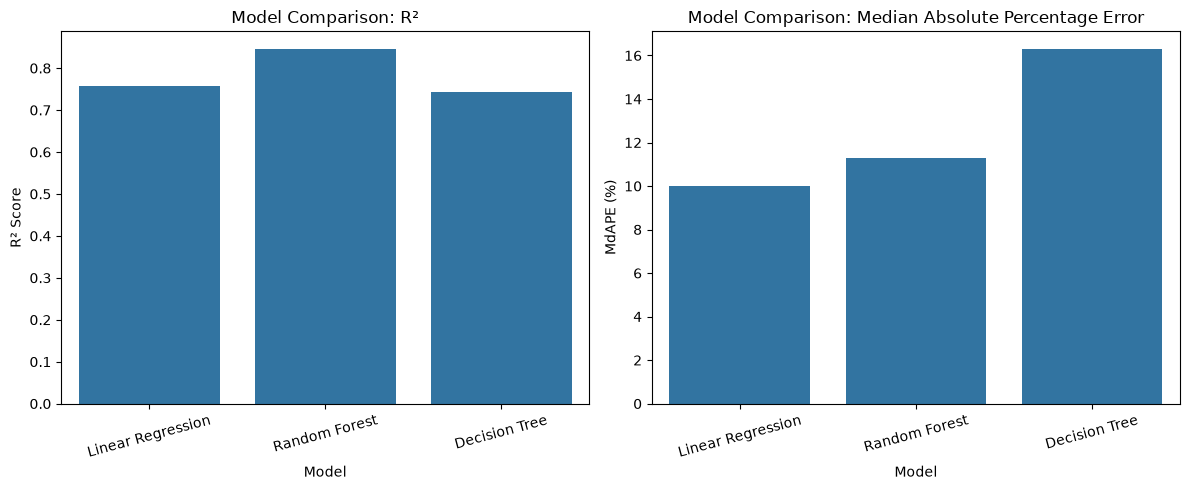

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# R² comparison: higher is better
sns.barplot(
    data=comparison,
    x="Model",
    y="R²",
    ax=axes[0]
)

axes[0].set_title("Model Comparison: R²")
axes[0].set_ylabel("R² Score")
axes[0].tick_params(axis="x", rotation=15)

# MdAPE comparison: lower is better
sns.barplot(
    data=comparison,
    x="Model",
    y="MdAPE (%)",
    ax=axes[1]
)

axes[1].set_title("Model Comparison: Median Absolute Percentage Error")
axes[1].set_ylabel("MdAPE (%)")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [28]:
models = {
    "Linear Regression": baseline_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest
}

overfitting_results = []

for name, model in models.items():

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Convert log predictions back to dollars
    if name == "Linear Regression":
        train_pred = np.exp(train_pred)
        test_pred = np.exp(test_pred)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    overfitting_results.append({
        "Model": name,
        "Train R²": train_r2,
        "Test R²": test_r2,
        "R² Gap": train_r2 - test_r2
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.round(4))


,Model,Train R²,Test R²,R² Gap
0,Linear Regression,0.6883,0.7582,-0.0699
1,Decision Tree,0.7992,0.7419,0.0572
2,Random Forest,0.9141,0.8455,0.0687


,Original Feature,Importance
1,BathroomsTotalInteger,0.2310
7,LivingArea,0.2284
8,Longitude,0.1745
6,Latitude,0.1623
4,CountyOrParish,0.0614
3,City,0.0357
15,YearBuilt,0.0326
10,MLSAreaMajor,0.0246
9,LotSizeSquareFeet,0.0221
13,PostalCode,0.0161


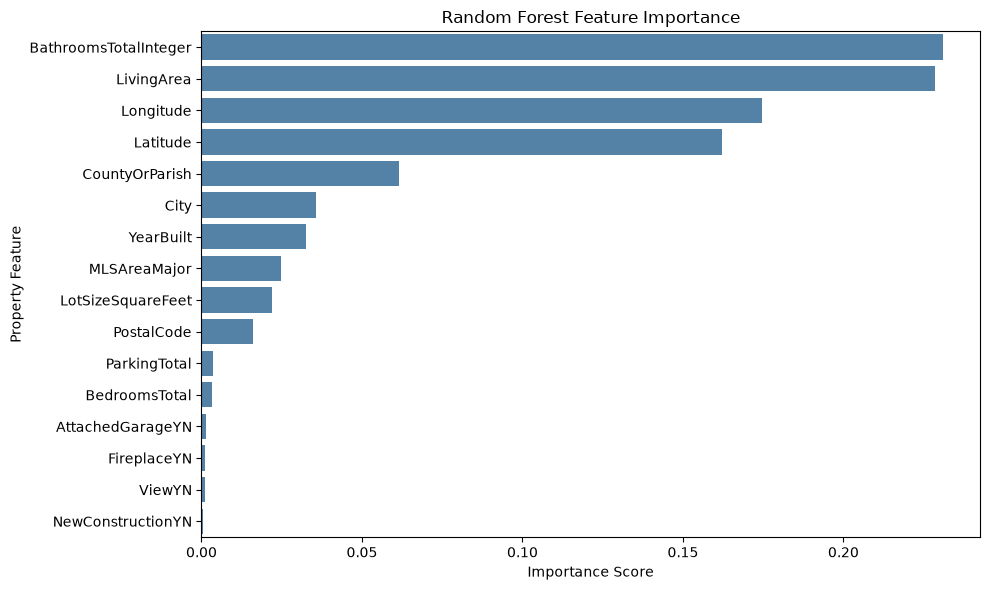

In [33]:
# Get trained Random Forest model and preprocessor
rf_model = random_forest.named_steps["model"]
rf_preprocessor = random_forest.named_steps["preprocessor"]

# Get feature importance scores
importances = rf_model.feature_importances_

# Get transformed feature names
feature_names = rf_preprocessor.get_feature_names_out()

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Group encoded features back into original property features
original_features = []

# Numeric features
original_features.extend(numeric_features)

# Categorical features expanded by OneHotEncoder
encoder = rf_preprocessor.named_transformers_["cat"].named_steps["onehot"]

for feature, categories in zip(categorical_features, encoder.categories_):
    original_features.extend([feature] * len(categories))

# Assign original feature names
feature_importance["Original Feature"] = original_features

# Sum importance across encoded categories
feature_importance = (
    feature_importance
    .groupby("Original Feature", as_index=False)["Importance"]
    .sum()
    .sort_values(by="Importance", ascending=False)
)

# Display feature importance
display(feature_importance.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Original Feature",
    color="steelblue"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Property Feature")
plt.tight_layout()
plt.show()

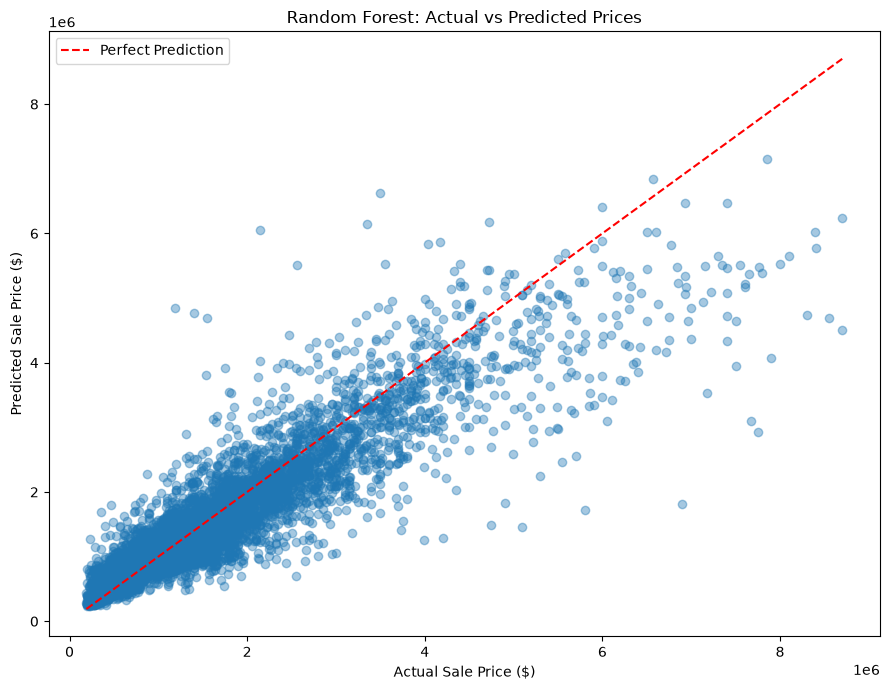

In [34]:

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.4
)

min_price = min(y_test.min(), rf_predictions.min())
max_price = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Random Forest: Actual vs Predicted Prices")
plt.legend()
plt.tight_layout()
plt.show()


In [38]:
# Identify the best-performing model based on test R²
best_model = comparison.iloc[0]

print("Best Model:", best_model["Model"])
print("Test R²:", round(best_model["R²"], 4))
print("MAE: ${:,.2f}".format(best_model["MAE"]))
print("RMSE: ${:,.2f}".format(best_model["RMSE"]))
print("MdAPE: {:.2f}%".format(best_model["MdAPE (%)"]))

# Retrieve Linear Regression baseline R²
baseline_r2 = comparison.loc[
    comparison["Model"] == "Linear Regression", "R²"
].iloc[0]

# Retrieve Decision Tree and Random Forest R²
dt_r2 = comparison.loc[
    comparison["Model"] == "Decision Tree", "R²"
].iloc[0]

rf_r2 = comparison.loc[
    comparison["Model"] == "Random Forest", "R²"
].iloc[0]

# Compare each model against the baseline
print("\nR² Improvement Over Baseline:")
print("Decision Tree:", round(dt_r2 - baseline_r2, 4))
print("Random Forest:", round(rf_r2 - baseline_r2, 4))

# Explain the winning model
if best_model["Model"] == "Random Forest":
    print("\nRandom Forest achieved the highest test R².")
    print("It explains more variation in property prices than the other models.")
else:
    print("\nThe best model based on test R² is:", best_model["Model"])

Best Model: Random Forest
Test R²: 0.8455
MAE: $209,565.40
RMSE: $390,223.43
MdAPE: 11.28%

R² Improvement Over Baseline:
Decision Tree: -0.0163
Random Forest: 0.0873

Random Forest achieved the highest test R².
It explains more variation in property prices than the other models.
